In [404]:
import numpy as np

class Variable:

  def __init__(self, value, children=(), op='base_var', label=''):
    self.value = value
    self.children = children
    self.op=op
    self.label = label
    if(op=='base_var' and label==''):
      #print("WARNING: Base vairable without label created. Please define Variable label seperately, else it will cause issues.");
      pass
    self.grad = 0
    self.back = lambda: None
    self.back_order =[]

  def __repr__(self):
    return f"Variable: {self.label}, Value: {self.value}, Operation: {self.op}, Grad: {self.grad}"

  def __add__(self, other):
    result = Variable(self.value+other.value, (self, other), '+', label = f"({self.label}+{other.label})")

    def back():
      self.grad += 1*result.grad
      other.grad += 1*result.grad

    result.back = back
    return result

  def __mul__(self, other):
    result = Variable(self.value*other.value, (self, other), '*',label = f"({self.label}*{other.label})")

    def back():
      self.grad += other.value*result.grad
      other.grad += self.value*result.grad

    result.back = back
    return result

  def sigmoid(self):
    result = Variable(1/(1+np.exp(-self.value)), children=(self,), op='sigmoid', label = f"sigmoid({self.label})")

    def back():
      self.grad += result.value*(1-result.value)*result.grad

    result.back = back

    return result

  def square_error(self, other):
    result = Variable((self.value-other.value)**2, children = (self, other), op = "square_error", label = f"MSE({self.label,other.label})")

    def back():
      self.grad += 2*(self.value-other.value)*result.grad
      other.grad += 2*(self.value-other.value)*result.grad

    result.back = back

    return result

  def backward(self):
    self.grad = 1

    self.back_order = []

    def topo(var):
      for child in var.children:
        topo(child)
      self.back_order.append(var)

    topo(self)

    for var in reversed(self.back_order):
      var.back()





In [233]:
#pip install treelib

In [405]:
from treelib import Tree

def display_tree(var):
  tree = Tree()
  tree.create_node(var.__repr__(), var.label)
  itr = [var]
  for i in itr:
    for j in i.children:
      tree.create_node(j.__repr__(), j.label, parent=i.label)
      itr.append(j)

  tree.show()



In [406]:
x1 = Variable(2)
x1.label = 'x1'
x1.op = 'input'
x2 = Variable(3)
x2.label = 'x2'
x2.op = 'input'
w1 = Variable(-3)
w1.label = 'w1'
w2 = Variable(1)
w2.label = 'w2'
b = Variable(3)
b.label = 'b'

x1w1 = x1*w1
x2w2 = x2*w2
dot = x1w1 + x2w2
sum = dot+b;
output = sum.sigmoid()
output.backward()

display_tree(output)

Variable: sigmoid((((x1*w1)+(x2*w2))+b)), Value: 0.5, Operation: sigmoid, Grad: 1
└── Variable: (((x1*w1)+(x2*w2))+b), Value: 0, Operation: +, Grad: 0.25
    ├── Variable: ((x1*w1)+(x2*w2)), Value: -3, Operation: +, Grad: 0.25
    │   ├── Variable: (x1*w1), Value: -6, Operation: *, Grad: 0.25
    │   │   ├── Variable: w1, Value: -3, Operation: base_var, Grad: 0.5
    │   │   └── Variable: x1, Value: 2, Operation: input, Grad: -0.75
    │   └── Variable: (x2*w2), Value: 3, Operation: *, Grad: 0.25
    │       ├── Variable: w2, Value: 1, Operation: base_var, Grad: 0.75
    │       └── Variable: x2, Value: 3, Operation: input, Grad: 0.25
    └── Variable: b, Value: 3, Operation: base_var, Grad: 0.25



In [408]:

x1w1 = x1*w1
x2w2 = x2*w2
dot = x1w1 + x2w2
sum = dot+b;
output = sum.sigmoid()
y = Variable(0)
y.label = 'y'
y.op = 'input'
loss = output.square_error(y)
loss.backward()

display_tree(loss)

Variable: MSE(('sigmoid((((x1*w1)+(x2*w2))+b))', 'y')), Value: 0.25, Operation: square_error, Grad: 1
├── Variable: sigmoid((((x1*w1)+(x2*w2))+b)), Value: 0.5, Operation: sigmoid, Grad: 1.0
│   └── Variable: (((x1*w1)+(x2*w2))+b), Value: 0, Operation: +, Grad: 0.25
│       ├── Variable: ((x1*w1)+(x2*w2)), Value: -3, Operation: +, Grad: 0.25
│       │   ├── Variable: (x1*w1), Value: -6, Operation: *, Grad: 0.25
│       │   │   ├── Variable: w1, Value: -3, Operation: base_var, Grad: 1.5
│       │   │   └── Variable: x1, Value: 2, Operation: input, Grad: -2.25
│       │   └── Variable: (x2*w2), Value: 3, Operation: *, Grad: 0.25
│       │       ├── Variable: w2, Value: 1, Operation: base_var, Grad: 2.25
│       │       └── Variable: x2, Value: 3, Operation: input, Grad: 0.75
│       └── Variable: b, Value: 3, Operation: base_var, Grad: 0.75
└── Variable: y, Value: 0, Operation: input, Grad: 1.0



In [421]:
import random

class Neuron:
  def __init__(self, n):
    self.n = n;
    self.weights = [Variable(random.uniform(-1,1)) for _ in range(n)]
    self.bias = Variable(random.uniform(-1,1))


  def __call__(self, x):
      sum = Variable(0,op='input', label='c0')
      for xi , w in zip(x, self.weights):
          sum += xi*w
      return (sum+self.bias).sigmoid()

  def parameters(self):
    return self.weights + [self.bias]



n1 = Neuron(3);
x = [Variable(random.uniform(-1,1)) for _ in range(3)]
"""
i = 0
for var in x:
  var.label = f'x{i}'
  var.op = 'input'
  i+=1
n1(x)"""

"\ni = 0\nfor var in x:\n  var.label = f'x{i}'\n  var.op = 'input'\n  i+=1\nn1(x)"

In [422]:
class Layer:
  def __init__(self, nin, nout):
    self.nin = nin
    self.nout = nout
    self.neurons = [Neuron(nin) for _ in range(nout)]

  def __call__(self, x):
    if(self.nout>1):
      return [neuron(x) for neuron in self.neurons]
    else:
      return self.neurons[0](x);

  def parameters(self):
    return [p for neuron in self.neurons for p in neuron.parameters()]

In [423]:
#layer = Layer(3, 3)
#layer(x)

In [437]:
class Network:
  def __init__(self, nin, nouts):
    sz = [nin] + nouts
    self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

  def __call__(self, x):
    xc = [Variable(var.value) for var in x]
    for layer in self.layers:
      xc = layer(xc)
    return xc

  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]

  def gradient_descent(self, lr):
    params = self.parameters()
    for p in params:
      p.value = p.value - lr*p.grad

  def zero_grad(self):
    params = self.parameters()
    for p in params:
      p.grad = 0


In [438]:
feature_count = 3
data_set_count = 4

x = [[Variable(random.uniform(0,1), op='input') for _ in range(feature_count)] for _ in range(data_set_count)]
y = [Variable(random.uniform(0,1), op = 'input') for _ in range(data_set_count)]

x

[[Variable: , Value: 0.47794084306343587, Operation: input, Grad: 0,
  Variable: , Value: 0.026171588302844162, Operation: input, Grad: 0,
  Variable: , Value: 0.970474588549949, Operation: input, Grad: 0],
 [Variable: , Value: 0.530408935288629, Operation: input, Grad: 0,
  Variable: , Value: 0.9861909633560539, Operation: input, Grad: 0,
  Variable: , Value: 0.2602118045456089, Operation: input, Grad: 0],
 [Variable: , Value: 0.38759473844985093, Operation: input, Grad: 0,
  Variable: , Value: 0.585628979605461, Operation: input, Grad: 0,
  Variable: , Value: 0.7018771030181301, Operation: input, Grad: 0],
 [Variable: , Value: 0.298417100427094, Operation: input, Grad: 0,
  Variable: , Value: 0.13318319108674204, Operation: input, Grad: 0,
  Variable: , Value: 0.5903207544646563, Operation: input, Grad: 0]]

In [447]:
network = Network(3,[3,1])
network.parameters()



[Variable: , Value: -0.6272235509868238, Operation: base_var, Grad: 0,
 Variable: , Value: -0.19274774898184943, Operation: base_var, Grad: 0,
 Variable: , Value: -0.8126206687049893, Operation: base_var, Grad: 0,
 Variable: , Value: -0.5924336449561651, Operation: base_var, Grad: 0,
 Variable: , Value: 0.7258209901820141, Operation: base_var, Grad: 0,
 Variable: , Value: -0.28869564527511904, Operation: base_var, Grad: 0,
 Variable: , Value: 0.9485344602410222, Operation: base_var, Grad: 0,
 Variable: , Value: -0.4733447621149187, Operation: base_var, Grad: 0,
 Variable: , Value: -0.29304630619249217, Operation: base_var, Grad: 0,
 Variable: , Value: 0.2223468233715229, Operation: base_var, Grad: 0,
 Variable: , Value: 0.14202657081930048, Operation: base_var, Grad: 0,
 Variable: , Value: -0.7397242864878764, Operation: base_var, Grad: 0,
 Variable: , Value: 0.2652641858967575, Operation: base_var, Grad: 0,
 Variable: , Value: 0.1657739121824282, Operation: base_var, Grad: 0,
 Variabl

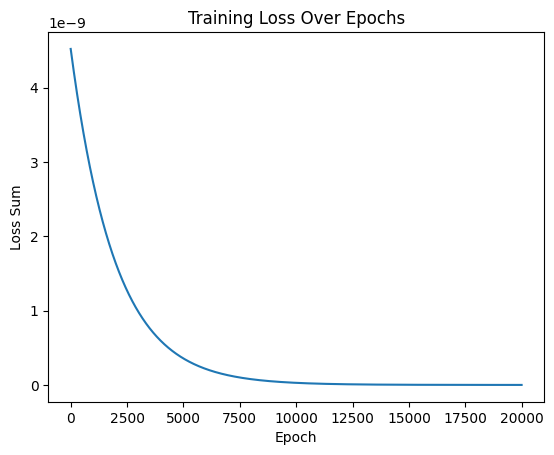

In [450]:
import matplotlib.pyplot as plt

epochs = 20000
loss_history = []

for _ in range(epochs):
    y_hat = [network(xi) for xi in x]
    err = [ y_hati.square_error(yi) for y_hati, yi in zip(y_hat, y)]
    err_sum = Variable(0, op = 'input')
    for e in err:
        err_sum += e
    err_sum.backward()
    network.gradient_descent(0.05)
    network.zero_grad()
    loss_history.append(err_sum.value)

plt.plot(loss_history)
plt.xlabel('Epoch')
plt.ylabel('Loss Sum')
plt.title('Training Loss Over Epochs')
plt.show()